# Heart Disease Prediction and Patient Risk Analysis – Sec E

## Step 1: Import libraries and load dataset

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

os.makedirs("output", exist_ok=True)

df = pd.read_csv("heart_disease_risk.csv")

print(df.shape)
print(df.head())
print(df.info())

(70000, 19)
   Chest_Pain  Shortness_of_Breath  Fatigue  Palpitations  Dizziness  \
0         0.0                  0.0      0.0           1.0        0.0   
1         0.0                  1.0      0.0           1.0        0.0   
2         1.0                  0.0      0.0           1.0        0.0   
3         1.0                  1.0      0.0           1.0        0.0   
4         0.0                  0.0      1.0           0.0        1.0   

   Swelling  Pain_Arms_Jaw_Back  Cold_Sweats_Nausea  High_BP  \
0       0.0                 0.0                 0.0      0.0   
1       0.0                 0.0                 0.0      1.0   
2       0.0                 0.0                 0.0      1.0   
3       0.0                 1.0                 1.0      1.0   
4       0.0                 0.0                 0.0      0.0   

   High_Cholesterol  Diabetes  Smoking  Obesity  Sedentary_Lifestyle  \
0               0.0       0.0      1.0      0.0                  1.0   
1               0.0       

## Step 2: Preprocess data (missing values, duplicates, outliers)

In [2]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

df = df.dropna()
df = df.drop_duplicates()

# Outliers: only Age is a continuous column; keep realistic ages
print("Age range:", df["Age"].min(), "-", df["Age"].max())
Q1, Q3 = df["Age"].quantile([0.25, 0.75])
IQR = Q3 - Q1
df = df[(df["Age"] >= Q1 - 1.5 * IQR) & (df["Age"] <= Q3 + 1.5 * IQR)]

# All columns are already numeric (0/1 and Age), so no encoding is needed
print("Clean shape:", df.shape)
df.to_csv("output/cleaned_data.csv", index=False)

Missing values: 0
Duplicates: 6245
Age range: 20.0 - 84.0
Clean shape: (63755, 19)


## Step 3: Analyze data (EDA) - 10 graphs

EDA 1: Heart Risk count | EDA 2: Age vs Heart Risk | EDA 3: Correlation heatmap | EDA 4: Age distribution | EDA 5: Risk by age group | EDA 6: Gender vs Heart Risk | EDA 7: Symptoms | EDA 8: Risk factors | EDA 9: Number of symptoms | EDA 10: Feature correlation

Heart_Risk
0.0    32268
1.0    31487
Name: count, dtype: int64


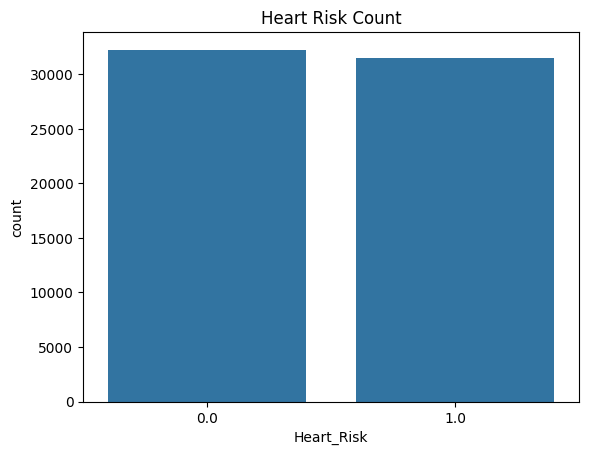

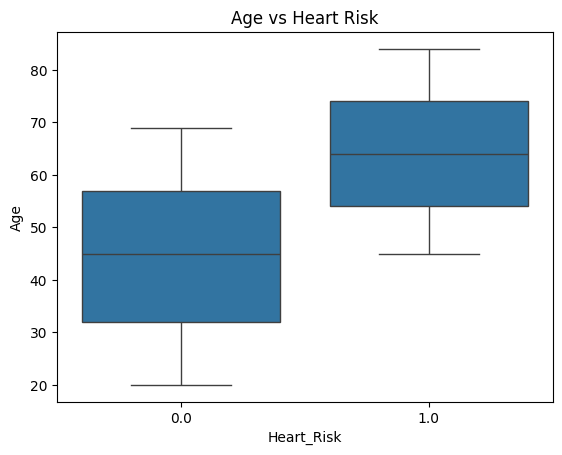

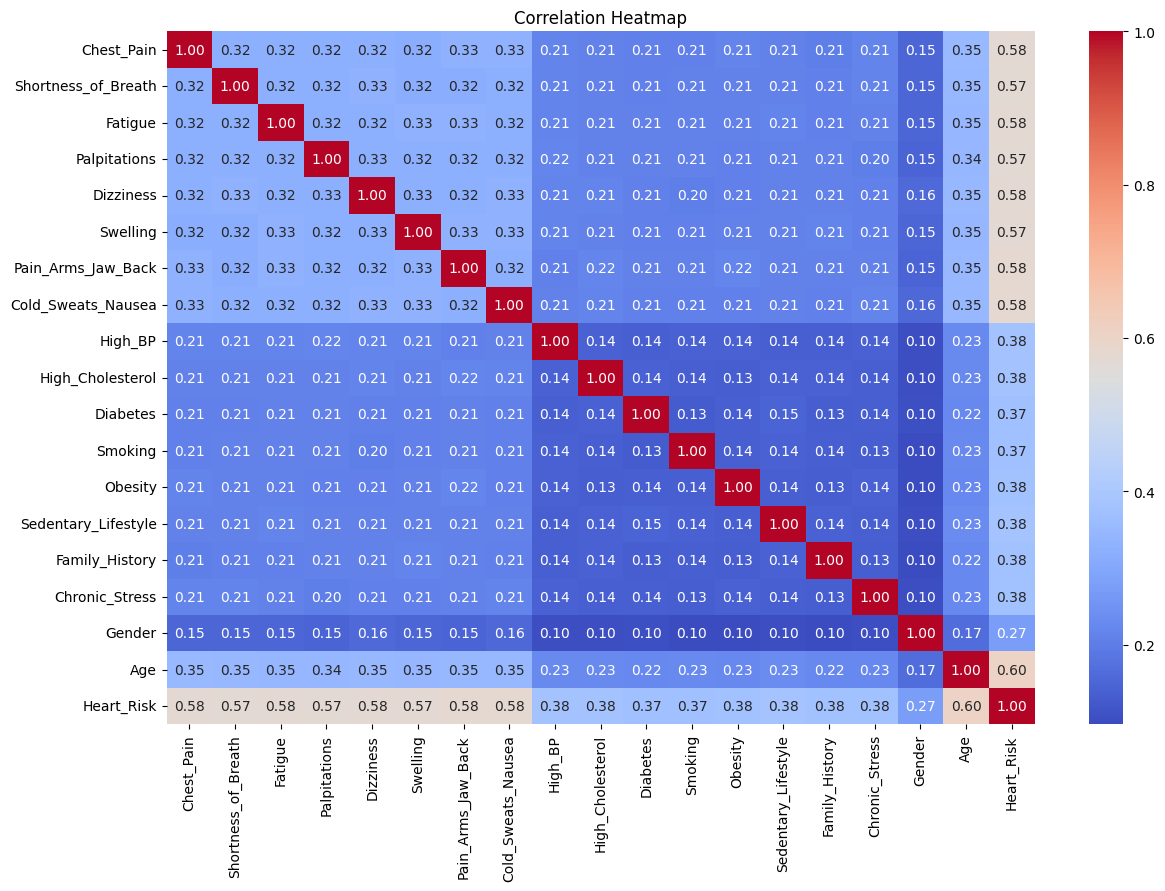

In [3]:
print(df["Heart_Risk"].value_counts())

sns.countplot(x="Heart_Risk", data=df)
plt.title("Heart Risk Count")
plt.savefig("output/heart_risk_count.png")
plt.show()

sns.boxplot(x="Heart_Risk", y="Age", data=df)
plt.title("Age vs Heart Risk")
plt.savefig("output/age_vs_risk.png")
plt.show()

plt.figure(figsize=(14, 9))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.savefig("output/correlation_heatmap.png")
plt.show()

### EDA 4: Age distribution by Heart Risk

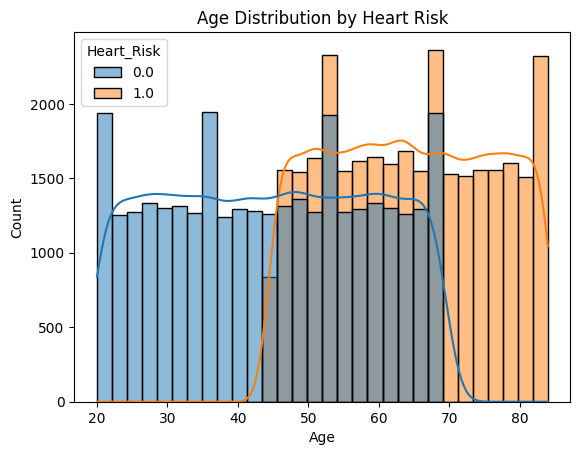

In [4]:
sns.histplot(data=df, x="Age", hue="Heart_Risk", bins=30, kde=True)
plt.title("Age Distribution by Heart Risk")
plt.savefig("output/eda4_age_distribution.png")
plt.show()

### EDA 5: Heart Risk rate by age group

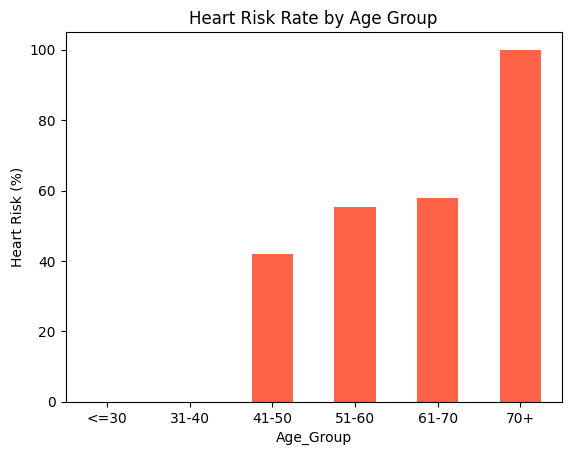

In [5]:
df_eda = df.copy()
df_eda["Age_Group"] = pd.cut(df_eda["Age"], bins=[0, 30, 40, 50, 60, 70, 120],
                             labels=["<=30", "31-40", "41-50", "51-60", "61-70", "70+"])
rate = df_eda.groupby("Age_Group", observed=True)["Heart_Risk"].mean() * 100
rate.plot(kind="bar", color="tomato")
plt.title("Heart Risk Rate by Age Group")
plt.ylabel("Heart Risk (%)")
plt.xticks(rotation=0)
plt.savefig("output/eda5_age_group.png")
plt.show()

### EDA 6: Gender vs Heart Risk

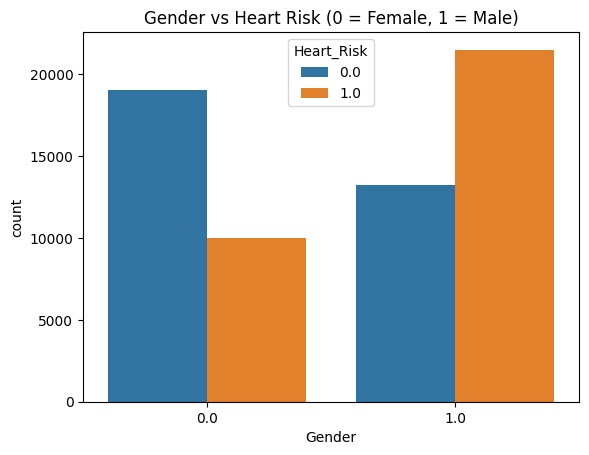

In [6]:
sns.countplot(x="Gender", hue="Heart_Risk", data=df)
plt.title("Gender vs Heart Risk (0 = Female, 1 = Male)")
plt.savefig("output/eda6_gender.png")
plt.show()

### EDA 7: Symptoms - patients with Heart Risk vs without

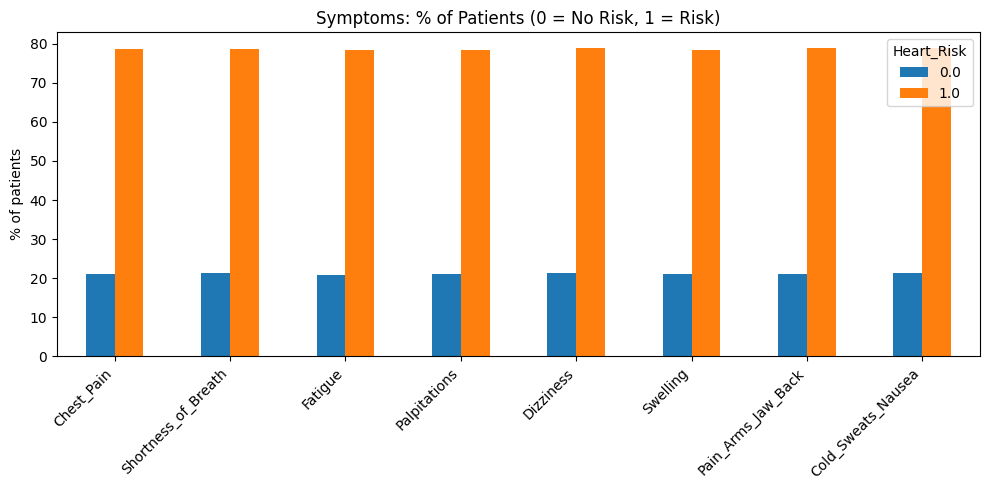

In [7]:
symptoms = ["Chest_Pain", "Shortness_of_Breath", "Fatigue", "Palpitations",
            "Dizziness", "Swelling", "Pain_Arms_Jaw_Back", "Cold_Sweats_Nausea"]

df.groupby("Heart_Risk")[symptoms].mean().T.mul(100).plot(kind="bar", figsize=(10, 5))
plt.title("Symptoms: % of Patients (0 = No Risk, 1 = Risk)")
plt.ylabel("% of patients")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("output/eda7_symptoms.png")
plt.show()

### EDA 8: Risk factors - patients with Heart Risk vs without

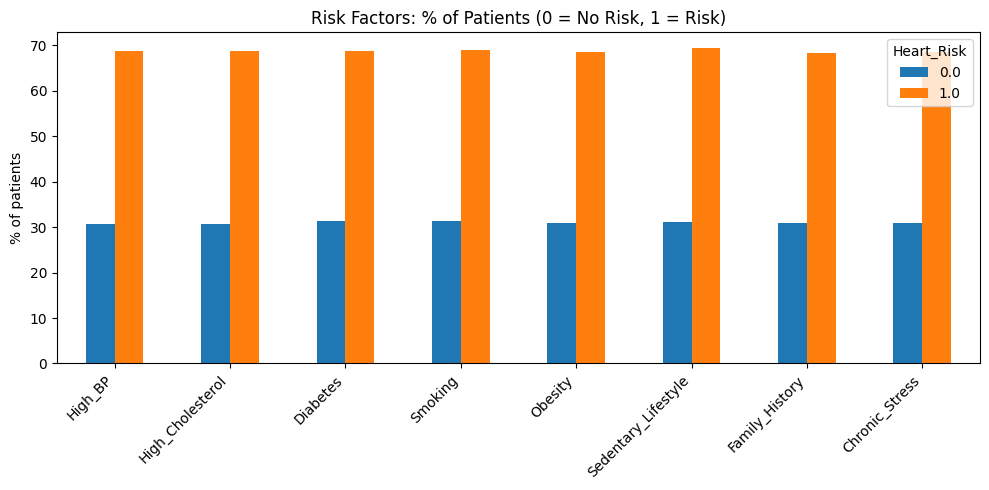

In [8]:
risk_factors = ["High_BP", "High_Cholesterol", "Diabetes", "Smoking",
                "Obesity", "Sedentary_Lifestyle", "Family_History", "Chronic_Stress"]

df.groupby("Heart_Risk")[risk_factors].mean().T.mul(100).plot(kind="bar", figsize=(10, 5))
plt.title("Risk Factors: % of Patients (0 = No Risk, 1 = Risk)")
plt.ylabel("% of patients")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("output/eda8_risk_factors.png")
plt.show()

### EDA 9: Number of symptoms vs Heart Risk

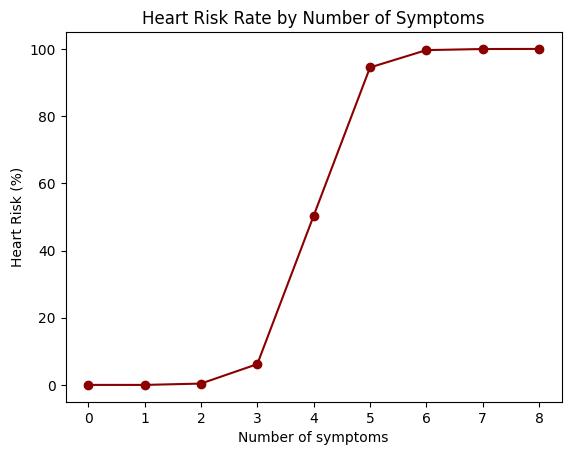

In [9]:
df_eda["Symptom_Count"] = df_eda[symptoms].sum(axis=1)
rate = df_eda.groupby("Symptom_Count")["Heart_Risk"].mean() * 100
rate.plot(kind="line", marker="o", color="darkred")
plt.title("Heart Risk Rate by Number of Symptoms")
plt.xlabel("Number of symptoms")
plt.ylabel("Heart Risk (%)")
plt.savefig("output/eda9_symptom_count.png")
plt.show()

### EDA 10: Connection of each feature with Heart Risk

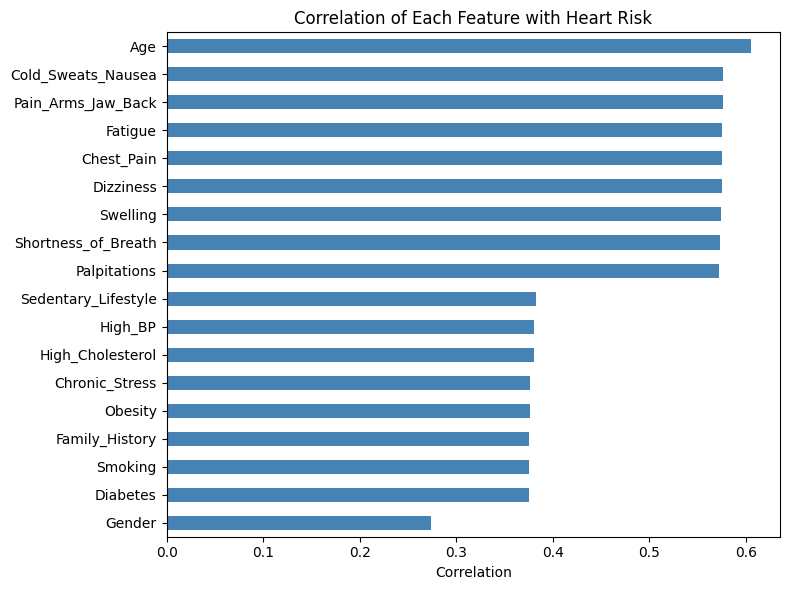

In [10]:
corr_bar = df.corr()["Heart_Risk"].drop("Heart_Risk").sort_values()
corr_bar.plot(kind="barh", figsize=(8, 6), color="steelblue")
plt.title("Correlation of Each Feature with Heart Risk")
plt.xlabel("Correlation")
plt.tight_layout()
plt.savefig("output/eda10_feature_correlation.png")
plt.show()

## Step 4: Select features (highest connection with Heart_Risk)

In [11]:
corr = df.corr()["Heart_Risk"].drop("Heart_Risk").abs().sort_values(ascending=False)
print((corr * 100).round(1))

# Keep only features with more than 50% connection to Heart_Risk
features = list(corr[corr > 0.5].index)
print("\nSelected features:", features)

Age                    60.5
Cold_Sweats_Nausea     57.6
Pain_Arms_Jaw_Back     57.6
Fatigue                57.6
Chest_Pain             57.5
Dizziness              57.5
Swelling               57.4
Shortness_of_Breath    57.3
Palpitations           57.2
Sedentary_Lifestyle    38.3
High_BP                38.1
High_Cholesterol       38.1
Chronic_Stress         37.7
Obesity                37.7
Family_History         37.5
Smoking                37.5
Diabetes               37.5
Gender                 27.4
Name: Heart_Risk, dtype: float64

Selected features: ['Age', 'Cold_Sweats_Nausea', 'Pain_Arms_Jaw_Back', 'Fatigue', 'Chest_Pain', 'Dizziness', 'Swelling', 'Shortness_of_Breath', 'Palpitations']


## Step 5: Split and scale the data

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[features]
y = df["Heart_Risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Training set:", X_train_s.shape)
print("Testing set:", X_test_s.shape)

Training set: (51004, 9)
Testing set: (12751, 9)


## Step 6: Build machine learning models

### 6.1 Logistic Regression (Yes / No prediction)

Logistic Regression Accuracy: 0.9792
              precision    recall  f1-score   support

         0.0       0.98      0.98      0.98      6454
         1.0       0.98      0.98      0.98      6297

    accuracy                           0.98     12751
   macro avg       0.98      0.98      0.98     12751
weighted avg       0.98      0.98      0.98     12751



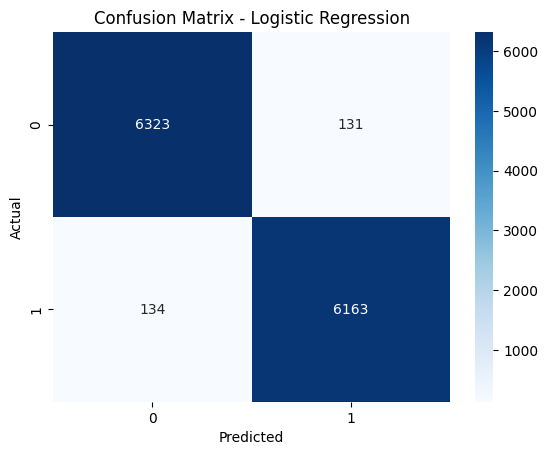

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_s, y_train)

y_pred = log_model.predict(X_test_s)
print("Logistic Regression Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig("output/confusion_matrix.png")
plt.show()

### 6.2 Linear Regression (risk score)

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

lin_model = LinearRegression()
lin_model.fit(X_train_s, y_train)

score_pred = lin_model.predict(X_test_s)
print("R2 Score:", round(r2_score(y_test, score_pred), 4))
print("MSE:", round(mean_squared_error(y_test, score_pred), 4))

R2 Score: 0.8312
MSE: 0.0422


### 6.3 KNN (find patients with similar conditions)

In [15]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_s, y_train)

knn_pred = knn_model.predict(X_test_s)
print("KNN Accuracy:", round(accuracy_score(y_test, knn_pred), 4))

# Example: 5 most similar patients to the first test patient
distances, indices = knn_model.kneighbors(X_test_s[:1])
print("\nTest patient:")
print(X_test.iloc[0])
print("\n5 similar patients from training data:")
print(X_train.iloc[indices[0]])

KNN Accuracy: 0.9784

Test patient:
Age                    24.0
Cold_Sweats_Nausea      0.0
Pain_Arms_Jaw_Back      0.0
Fatigue                 1.0
Chest_Pain              0.0
Dizziness               0.0
Swelling                0.0
Shortness_of_Breath     0.0
Palpitations            0.0
Name: 51462, dtype: float64

5 similar patients from training data:
        Age  Cold_Sweats_Nausea  Pain_Arms_Jaw_Back  Fatigue  Chest_Pain  \
59791  24.0                 0.0                 0.0      1.0         0.0   
4976   24.0                 0.0                 0.0      1.0         0.0   
10249  24.0                 0.0                 0.0      1.0         0.0   
10788  24.0                 0.0                 0.0      1.0         0.0   
46243  24.0                 0.0                 0.0      1.0         0.0   

       Dizziness  Swelling  Shortness_of_Breath  Palpitations  
59791        0.0       0.0                  0.0           0.0  
4976         0.0       0.0                  0.0           0

### 6.4 K-Means Clustering (Low / Medium / High risk)

In [16]:
from sklearn.cluster import KMeans

# Cluster patients using their predicted risk score (0-100)
train_scores = np.clip(lin_model.predict(X_train_s), 0, 1).reshape(-1, 1) * 100

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(train_scores)

# Name clusters by their average score: lowest = Low, middle = Medium, highest = High
order = np.argsort(kmeans.cluster_centers_.flatten())
cluster_name = {order[0]: "Low", order[1]: "Medium", order[2]: "High"}

for c in order:
    print(cluster_name[c], "risk cluster centre:", round(kmeans.cluster_centers_[c][0], 2))

Low risk cluster centre: 7.88
Medium risk cluster centre: 51.18
High risk cluster centre: 92.53


## Step 7: Optimize the model (cross-validation and tuning)

In [17]:
from sklearn.model_selection import cross_val_score, GridSearchCV

# 5-fold cross-validation
for name, model in [("Logistic Regression", log_model), ("KNN", knn_model)]:
    cv = cross_val_score(model, X_train_s, y_train, cv=5, scoring="accuracy")
    print(name, "CV accuracy:", round(cv.mean(), 4), "+/-", round(cv.std(), 4))

# Tune Logistic Regression
grid_log = GridSearchCV(
    LogisticRegression(max_iter=1000),
    {"C": [0.01, 0.1, 1, 10, 100]},
    cv=5, scoring="accuracy"
)
grid_log.fit(X_train_s, y_train)
print("\nBest Logistic params:", grid_log.best_params_, "CV acc:", round(grid_log.best_score_, 4))

# Tune KNN
grid_knn = GridSearchCV(
    KNeighborsClassifier(),
    {"n_neighbors": [3, 5, 7, 11, 15]},
    cv=3, scoring="accuracy"
)
grid_knn.fit(X_train_s, y_train)
print("Best KNN params:", grid_knn.best_params_, "CV acc:", round(grid_knn.best_score_, 4))

best_log = grid_log.best_estimator_
print("\nTuned Logistic test accuracy:", round(accuracy_score(y_test, best_log.predict(X_test_s)), 4))
print("Tuned KNN test accuracy:", round(accuracy_score(y_test, grid_knn.best_estimator_.predict(X_test_s)), 4))

Logistic Regression CV accuracy: 0.9769 +/- 0.0013
KNN CV accuracy: 0.9741 +/- 0.0008

Best Logistic params: {'C': 1} CV acc: 0.9769
Best KNN params: {'n_neighbors': 3} CV acc: 0.9743

Tuned Logistic test accuracy: 0.9792
Tuned KNN test accuracy: 0.9775


## Step 8: Display results (user enters patient data)

In [18]:
def predict_patient(patient):
    p = pd.DataFrame([patient])[features]
    p_s = scaler.transform(p)

    prediction = "Yes" if best_log.predict(p_s)[0] == 1 else "No"
    risk_score = float(np.clip(lin_model.predict(p_s)[0], 0, 1) * 100)
    category = cluster_name[kmeans.predict([[risk_score]])[0]]

    print("\n----- Patient Input -----")
    for name, value in patient.items():
        print(f"{name:<22}: {value}")

    print("\n----- Result -----")
    print("Heart Disease Prediction :", prediction)
    print("Patient Risk Score       :", round(risk_score, 2), "%")
    print("Patient Risk Category    :", category)


# Enter patient data
patient = {}
for col in features:
    if col == "Age":
        patient[col] = int(input("Enter Age: "))
    else:
        patient[col] = int(input(f"{col} (1 = Yes, 0 = No): "))

predict_patient(patient)


----- Patient Input -----
Age                   : 700
Cold_Sweats_Nausea    : 1
Pain_Arms_Jaw_Back    : 1
Fatigue               : 0
Chest_Pain            : 1
Dizziness             : 0
Swelling              : 0
Shortness_of_Breath   : 0
Palpitations          : 1

----- Result -----
Heart Disease Prediction : Yes
Patient Risk Score       : 100.0 %
Patient Risk Category    : High


## Step 9: Save the models

In [19]:
joblib.dump(best_log, "output/logistic_model.pkl")
joblib.dump(lin_model, "output/linear_model.pkl")
joblib.dump(knn_model, "output/knn_model.pkl")
joblib.dump(kmeans, "output/kmeans_model.pkl")
joblib.dump(scaler, "output/scaler.pkl")
print("Models saved in the output folder")

Models saved in the output folder
